# RQ1 · Step 3: Lock in the measuring protocol

**Goal:** one fixed way of measuring lesions, written once in `code/fidelity/measure.py`, so every later
experiment (clean-image control, degradation grid, trajectories) measures *exactly* the same way.

**What this notebook does**
1. Prints the protocol, the rules every experiment follows
2. **Test A, reproduction:** the module must reproduce your Step 2 `rt_1024` and `rt_512` numbers
3. **Test B, identity:** comparing an image with itself must show no lost and no new lesions
4. **Test C, sensitivity:** a known damage (blur) must be detected, more for small lesions than large ones
5. Saves the protocol record and test results

**Done when:** all three tests print `PASS`, and you've looked at the picture in Test C.

Runs on your Mac (MPS). About 60 segmentations at 1024 with flip averaging, so a few minutes.

In [2]:
import sys, json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from tqdm.auto import tqdm

CODE = Path.cwd().parent                 # .../fidelity-midl/code  (this notebook lives in code/notebooks)
sys.path.insert(0, str(CODE))
from fidelity import measure as M

# >>> EDIT THESE if your folders differ
IDRID  = CODE.parent / "data/raw/idrid/A. Segmentation"
STEP2  = CODE.parent / "results/Idrid/step2_toolkit_tta"
OUT    = CODE.parent / "results/Idrid/step3_protocol"
OUT.mkdir(parents=True, exist_ok=True)
N_TEST = 5                               # images used for the tests

images, masks = M.find_idrid(IDRID)
test_ids = sorted(images)[:N_TEST]
print(f"{len(images)} IDRiD images found | testing on {test_ids}")
print("Step 2 results found:", (STEP2 / "per_image.csv").exists())

81 IDRiD images found | testing on ['IDRiD_01', 'IDRiD_02', 'IDRiD_03', 'IDRiD_04', 'IDRiD_05']
Step 2 results found: True


/Users/atharvax/dev/MIDL/fidelity-midl/code/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. The protocol

| Rule | Setting | Why |
|---|---|---|
| Frame | crop black borders (toolkit rule), resize longest side, pad to square | keeps lesions round; same geometry for image and masks |
| Restorers work at | **512** | Step 2 decision: within 1.5 points of 1024 for MAs |
| Segmenter runs at | **1024**, working images enlarged to it (like `rt_*`) | small inputs fed directly confuse the model (`direct_512` failed) |
| Weights | **never trained on the measured dataset** (IDRiD → DDR weights) | no leakage |
| Flip averaging | **on** (4 flips) | cancels the model's ~1-pixel offset |
| Lesion | one 8-connected blob | |
| Found / correct | any pixel overlap of the same type | same as Step 2 |
| New detection | restored-only blob, touching no clean detection, inside the eye shrunk by 1% | hallucination candidate, border artefacts ignored |

In [3]:
seg = M.Segmenter("IDRID")               # picks DDR weights automatically
record = M.protocol_record(seg)
print(json.dumps(record, indent=2, default=str))

{
  "protocol_version": "1.0 (2026-10-31)",
  "work_size": 512,
  "seg_size": 1024,
  "lesion_labels": {
    "SE": 1,
    "EX": 2,
    "HE": 3,
    "MA": 4
  },
  "size_bins": [
    "<10",
    "10-20",
    "20-40",
    "40-80",
    ">=80"
  ],
  "fov_erode_frac": 0.01,
  "matching": "8-connected components; found/correct = any pixel overlap of the same type",
  "safe_weights": {
    "IDRID": "DDR",
    "DDR": "IDRID"
  },
  "dataset": "IDRID",
  "weights": "DDR",
  "tta": true,
  "device": "mps"
}


## 2. Test A: does the module reproduce Step 2?

The module's 1024 and 512 paths are the same as Step 2's `rt_1024` and `rt_512` arms. On the same images it
should give (almost) the same counts. Tiny differences are allowed: Step 2 rounded one image size with Python's
`round`, the module uses OpenCV's exact rule, which can move a border by one pixel.

**Pass rule:** for each lesion type, total found and total predicted within **2%** of Step 2.

In [4]:
cache = {}                               # (image_id, size) -> native label map, reused in Tests B and C
rows = []
t0 = time.time()
for image_id in tqdm(test_ids, desc="Test A"):
    photo = M.load_photo(images[image_id])
    frame = M.Frame.from_photo(photo)
    truths = M.load_truths(masks[image_id], photo.shape[:2])
    for size in (1024, 512):
        labels = seg.labels(frame.to_square(photo, size), frame)
        cache[image_id, size] = labels
        img_rows, _ = M.score_vs_truth(labels, truths)
        rows += [dict(image_id=image_id, arm=f"rt_{size}", **r) for r in img_rows]
print(f"{time.time() - t0:.0f} s")

mine = pd.DataFrame(rows)
step2 = pd.read_csv(STEP2 / "per_image.csv")
step2 = step2[step2.image_id.isin(test_ids) & step2.arm.isin(["rt_1024", "rt_512"])]
cols = ["n_true", "n_found", "n_pred", "n_pred_correct"]
a = mine.groupby(["arm", "lesion"])[cols].sum()
b = step2.groupby(["arm", "lesion"])[cols].sum()
comp = a.join(b, rsuffix="_step2")
for c in ("n_found", "n_pred"):
    comp[f"{c}_diff_%"] = (100 * (comp[c] - comp[f"{c}_step2"]) / comp[f"{c}_step2"].clip(lower=1)).round(1)
display(comp)
ok_truth = (comp.n_true == comp.n_true_step2).all()
ok_close = (comp[["n_found_diff_%", "n_pred_diff_%"]].abs() <= 2).all().all()
print("Same true lesions as Step 2:", ok_truth)
print("TEST A:", "PASS" if ok_truth and ok_close else "CHECK: differences above 2%, send this table to Claude")

Test A:   0%|                                                                                    | 0/5 [00:00<?, ?it/s]Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.
/Users/atharvax/dev/MIDL/fidelity-midl/code/.venv/lib/python3.12/site-packages/fundus_lesions_toolkit/models/segmentation.py:190: UserWarning: Setting dropout to 0.2
  warnings.warn(f"Setting dropout to {initial_value}")
Test A: 100%|████████████████████████████████████████████████████████████████████████████| 5/5 [00:14<00:00,  2.80s/it]

14 s



/var/folders/dt/_jymhl_n7k7by5rpm7pmf4s80000gn/T/ipykernel_6105/486353450.py:21: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  comp = a.join(b, rsuffix="_step2")


n_true  n_found  n_pred  n_pred_correct  n_true_step2  \
arm     lesion                                                          
rt_1024 EX         687      226     227             222           687   
        HE         130       37      55              34           130   
        MA         133       36      63              37           133   
        SE           1        1       2               1             1   
rt_512  EX         687      207     207             203           687   
        HE         130       36      57              33           130   
        MA         133       30      52              30           133   
        SE           1        1       2               1             1   

                n_found_step2  n_pred_step2  n_pred_correct_step2  \
arm     lesion                                                      
rt_1024 EX                226           227                   222   
        HE                 37            55                    34   
        MA                 36            63                    37   
        SE                  1             2                     1   
rt_512  EX                207           207                   203   
        HE                 36            57                    33   
        MA                 30            52                    30   
        SE                  1             2                     1   

                n_found_diff_%  n_pred_diff_%  
arm     lesion                                 
rt_1024 EX                 0.0            0.0  
        HE                 0.0            0.0  
        MA                 0.0            0.0  
        SE                 0.0            0.0  
rt_512  EX                 0.0            0.0  
        HE                 0.0            0.0  
        MA                 0.0            0.0  
        SE                 0.0            0.0

Same true lesions as Step 2: True
TEST A: PASS


## 3. Test B: identity

Compare the clean 512 prediction with **itself**. Every clean detection must persist, there must be zero new
detections, and no true lesion may count as erased. If this fails, the comparison code is wrong.

In [5]:
fails = 0
for image_id in test_ids:
    photo = M.load_photo(images[image_id])
    frame = M.Frame.from_photo(photo)
    truths = M.load_truths(masks[image_id], photo.shape[:2])
    lab = cache[image_id, 512]
    summary, lesions = M.compare_clean_restored(lab, lab, truths, frame.fov(photo))
    s = pd.DataFrame(summary)
    erased = sum(l["found_clean"] and not l["found_restored"] for l in lesions)
    fails += int((s.persisting != s.clean_detections).any() or s.new_detections.sum() > 0 or erased > 0)
print("TEST B:", "PASS" if fails == 0 else f"FAIL on {fails} images")

TEST B: PASS


## 4. Test C: does the measure notice real damage?

We blur the 512 working image a little (Gaussian, sigma 1.5 px at 512), as a stand-in for a bad restorer,
and compare it with the clean image. Expected:
- some lesions are **lost**, and **small ones (microaneurysms) much more than large ones (haemorrhages)**
- few or no **new** detections, since blur removes detail rather than adding it

This proves the measure responds to damage in the way we expect *before* we trust it on restorers.

In [6]:
SIGMA = 1.5
lesion_rows, summ_rows = [], []
for image_id in tqdm(test_ids, desc="Test C"):
    photo = M.load_photo(images[image_id])
    frame = M.Frame.from_photo(photo)
    truths = M.load_truths(masks[image_id], photo.shape[:2])
    sq = frame.to_square(photo, 512)
    blurred = cv2.GaussianBlur(sq, (0, 0), SIGMA)
    lab_b = seg.labels(blurred, frame)
    cache[image_id, "blur"] = lab_b
    summary, lesions = M.compare_clean_restored(cache[image_id, 512], lab_b, truths, frame.fov(photo))
    summ_rows += [dict(image_id=image_id, **r) for r in summary]
    lesion_rows += [dict(image_id=image_id, **r) for r in lesions]

les = pd.DataFrame(lesion_rows)
les["size_bin"] = M.size_bin(les.area)
seen = les[les.found_clean]                                  # erasure is only defined for lesions seen on clean
by_type = seen.groupby("lesion").found_restored.agg(n_seen_clean="size", kept="mean")
by_type["lost_%"] = (100 * (1 - by_type.kept)).round(1)
display(by_type.drop(columns="kept"))
by_size = seen[seen.lesion == "MA"].groupby("size_bin", observed=True).found_restored.agg(n="size", kept="mean")
by_size["lost_%"] = (100 * (1 - by_size.kept)).round(1)
print("Microaneurysms lost by size:"); display(by_size.drop(columns="kept"))
new = pd.DataFrame(summ_rows).groupby("lesion")[["clean_detections", "new_detections"]].sum()
print("New detections after blur:"); display(new)

ma_lost = by_type.loc["MA", "lost_%"] if "MA" in by_type.index else np.nan
he_lost = by_type.loc["HE", "lost_%"] if "HE" in by_type.index else np.nan
print("TEST C:", "PASS" if ma_lost > he_lost else "CHECK: MAs not lost more than HEs, send these tables to Claude")

Test C: 100%|████████████████████████████████████████████████████████████████████████████| 5/5 [00:09<00:00,  1.91s/it]


,n_seen_clean,lost_%
lesion,,
EX,207,66.7
HE,36,22.2
MA,30,93.3
SE,1,0.0


Microaneurysms lost by size:


,n,lost_%
size_bin,,
10-20,15,100.0
20-40,15,86.7


New detections after blur:


,clean_detections,new_detections
lesion,,
EX,207,0
HE,57,6
MA,52,0
SE,2,4


TEST C: PASS


### See it

Microaneurysms on one image: **green = kept**, **red = lost after blur**, **blue = new after blur**.
Zoomed on the area with the most microaneurysms.

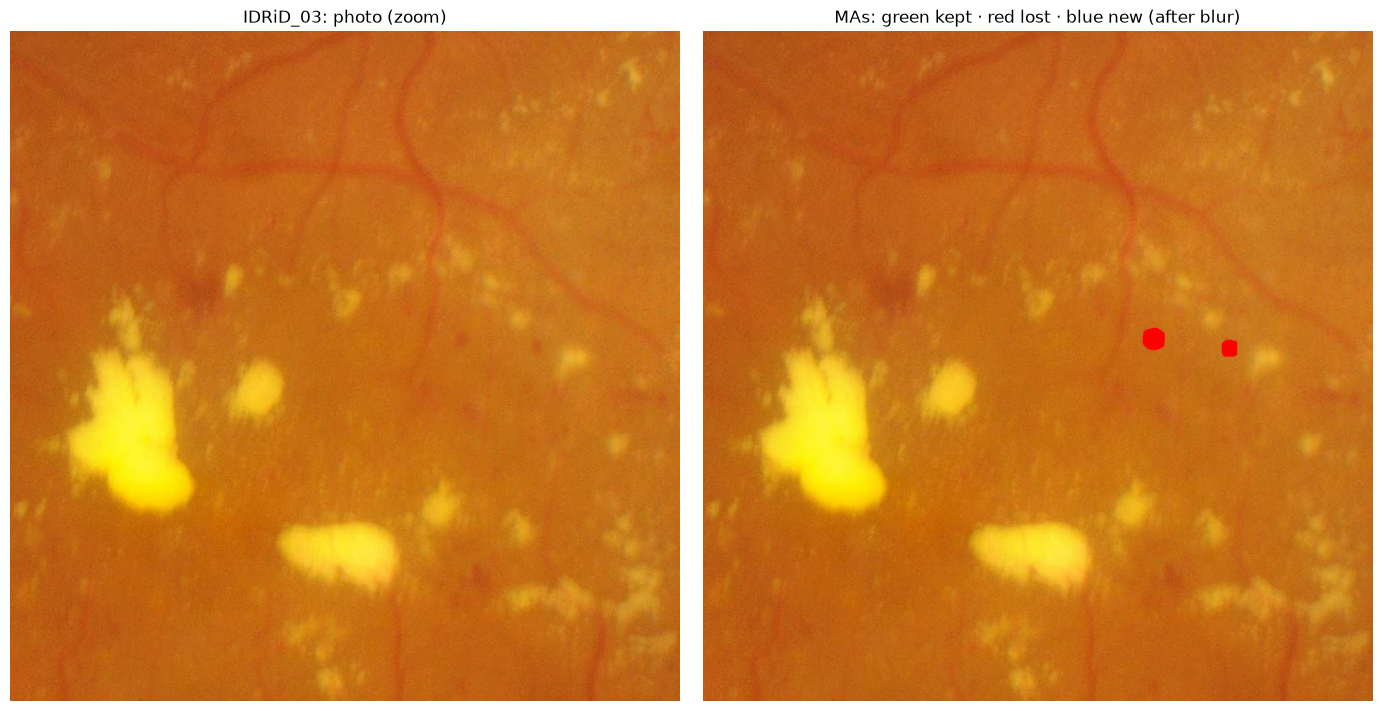

In [7]:
image_id = les[les.lesion == "MA"].groupby("image_id").size().idxmax()
photo = M.load_photo(images[image_id])
truths = M.load_truths(masks[image_id], photo.shape[:2])
gt_lab, n = M.components(truths["MA"])
li = les[(les.image_id == image_id) & (les.lesion == "MA")].set_index("lesion_idx")
kept = np.isin(gt_lab, li.index[li.found_clean & li.found_restored])
lost = np.isin(gt_lab, li.index[li.found_clean & ~li.found_restored])
clean_ma, blur_ma = cache[image_id, 512] == 4, cache[image_id, "blur"] == 4
c_lab, _ = M.components(clean_ma); r_lab, n_r = M.components(blur_ma)
touch = np.zeros(n_r + 1, bool); touch[np.unique(r_lab[clean_ma])] = True
new = (r_lab > 0) & ~touch[r_lab]

over = photo.copy()
for m, col in ((kept, (0, 255, 0)), (lost, (255, 0, 0)), (new, (0, 120, 255))):
    over[cv2.dilate(m.astype(np.uint8), np.ones((9, 9), np.uint8)) > 0] = col
ys, xs = np.nonzero(truths["MA"])
cy, cx = int(np.median(ys)), int(np.median(xs))
win = 500
box = (slice(max(cy - win, 0), cy + win), slice(max(cx - win, 0), cx + win))
fig, ax = plt.subplots(1, 2, figsize=(14, 7))
ax[0].imshow(photo[box]); ax[0].set_title(f"{image_id}: photo (zoom)")
ax[1].imshow(over[box]); ax[1].set_title("MAs: green kept · red lost · blue new (after blur)")
for a in ax: a.axis("off")
plt.tight_layout(); fig.savefig(OUT / "test_c_overlay.png", dpi=130); plt.show()

## 5. Save the protocol record

This file is the reference for every later result: if the numbers ever change, compare against it.

In [8]:
record.update(test_images=test_ids, blur_sigma_test_c=SIGMA,
              test_a=comp.reset_index().to_dict(orient="records"),
              test_c_lost_by_type=by_type.reset_index().to_dict(orient="records"))
(OUT / "protocol.json").write_text(json.dumps(record, indent=2, default=str))
comp.to_csv(OUT / "test_a_reproduction.csv")
by_type.to_csv(OUT / "test_c_lost_by_type.csv")
print("Saved to", OUT)

Saved to /Users/atharvax/dev/MIDL/fidelity-midl/results/Idrid/step3_protocol


## 6. What to send back, and what to log

Send Claude: the three `TEST` lines, the Test A table, and the Test C tables + picture.

**Log line:** `YYYY-MM-DD · Step 3 · measuring protocol v1.0 locked (512 work / 1024 seg / DDR weights / flip TTA) · tests A/B/C: __/__/__`

**Next:** Step 4, the clean-image control: clean IDRiD images through each restorer, measured with this protocol.